<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Baseline y filtrado colaborativo por vecindario</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Protocolo de evaluación, modelo de media más sesgos regularizados sobre los 99 millones de ratings y kNN ítem-ítem con similitud coseno y Pearson centrada sobre la submuestra S.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Construir los dos primeros sistemas de recomendación y el **protocolo de evaluación** que usan todos los demás:

- un **baseline** de media global más sesgos de usuario y de película, regularizados, entrenado sobre los 99 millones de
  ratings (Koren, 2008, sección 2.1);
- **filtrado colaborativo por vecindario ítem-ítem** (Leskovec *et al.*, *Mining of Massive Datasets*, cap. 9; Koren,
  2008, sección 2.2), con similitud coseno y Pearson centrada, sobre la submuestra S.

### Los datos

Usamos las salidas de `01_carga_eda.ipynb` en `data/processed/`: la matriz de entrenamiento completa `R_train.npz`
(480,189 × 17,770) con sus días `dias_csr.npy`, los arreglos `probe_*.npy`, la submuestra `S_R_train.npz`
(100,000 × 5,000) con sus días y su probe `S_probe_*.npy` (262,954 ratings).

**Regla de respaldo.** Cuando un modelo no puede predecir (usuario sin ratings, película sin vecinos con similitud
positiva), usa la predicción del baseline. Así ningún rating del probe queda sin predecir.

### Contenido

1. **Protocolo de evaluación.** Conjunto de validación tipo probe para ajustar hiperparámetros, RMSE y métricas top-N.
2. **Baseline.** Ajuste de los sesgos por mínimos cuadrados alternados, elección de $\lambda$, RMSE en el probe completo
   y en el de S, y comparación con Cinematch.
3. **kNN ítem-ítem.** Similitudes coseno y Pearson centrada con *shrinkage*, elección de $k$ y $\lambda$, RMSE, top-N
   y vecinos de algunas películas.
4. **Resumen.**

In [1]:
# Librerías, rutas, paleta y funciones auxiliares
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import psutil
import matplotlib.pyplot as plt
from numba import njit, prange
from scipy.linalg.blas import ssyrk
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

RUTA_PROCESADOS = Path("..") / "data" / "processed"
RUTA_RESULTADOS = RUTA_PROCESADOS / "resultados"      # métricas de cada modelo (.json)
RUTA_PREDICCIONES = RUTA_PROCESADOS / "predicciones"  # predicciones sobre el probe (.npy)
RUTA_MODELOS = RUTA_PROCESADOS / "modelos"            # parámetros de cada modelo
for ruta in [RUTA_RESULTADOS, RUTA_PREDICCIONES, RUTA_MODELOS]:
    ruta.mkdir(exist_ok=True)
SEMILLA = 42
CINEMATCH_PROBE = 0.9474

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    # Estilo común de los ejes: título, etiquetas, sin bordes superior y derecho, rejilla tenue
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    return f"{100 * x:,.{dec}f} %"


def tamano(nbytes):
    return f"{nbytes / 1e9:,.2f} GB" if nbytes >= 1e9 else f"{nbytes / 1e6:,.1f} MB"


registro_ram = []


def ram(paso):
    # Memoria del proceso (RSS) y memoria libre del sistema al terminar un paso
    rss, libre = psutil.Process().memory_info().rss, psutil.virtual_memory().available
    registro_ram.append({"paso": paso, "RAM del proceso": tamano(rss), "RAM libre del sistema": tamano(libre)})
    print(f"[RAM] {paso}: proceso {tamano(rss)} | libre en el sistema {tamano(libre)}")


def rmse(pred, real):
    return float(np.sqrt(np.mean((np.clip(pred, 1, 5) - real) ** 2)))


def guardar_resultado(modelo, **metricas):
    # Una fila de la tabla comparativa final (notebook 6)
    with open(RUTA_RESULTADOS / f"{modelo}.json", "w", encoding="utf-8") as f:
        json.dump({"modelo": modelo, **metricas}, f, ensure_ascii=False, indent=1)


ram("inicio")

[RAM] inicio: proceso 179.0 MB | libre en el sistema 5.72 GB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">RECOMENDACIÓN · EVALUACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Protocolo de evaluación</span></div>



**Validación tipo probe.** Los hiperparámetros (regularización, número de vecinos) **no** se eligen con el probe, que
es el conjunto de prueba. Separamos del entrenamiento un conjunto de validación que imita al probe: el **rating más
reciente de cada usuario** con al menos dos ratings (empates en el mismo día resueltos con un *hash* fijo de la
posición). Los modelos se ajustan sin esos ratings, se elige la configuración con menor RMSE de validación y después se
reentrenan con todo el entrenamiento para predecir el probe.

**Métricas.**

- **Predicción:** $\text{RMSE} = \sqrt{\frac{1}{|T|}\sum_{(u,i) \in T} (\hat r_{ui} - r_{ui})^2}$, con las predicciones
  recortadas a $[1, 5]$.
- **Top-N:** para 5,000 usuarios de S elegidos al azar (semilla 42) entre los que tienen en su probe de S al menos una
  película con rating ≥ 4, cada modelo ordena las películas de S que el usuario **no** calificó en el entrenamiento.
  Son **relevantes** las del probe con rating ≥ 4. Con $K = 10$:
  - $\text{Precision@}K = \frac{|\text{top-}K \cap \text{rel}|}{K}$;
  - $\text{Recall@}K = \frac{|\text{top-}K \cap \text{rel}|}{|\text{rel}|}$;
  - $\text{NDCG@}K = \frac{\sum_{j=1}^{K} \mathbb{1}[\text{relevante en } j] / \log_2(j+1)}{\sum_{j=1}^{\min(K, |\text{rel}|)} 1 / \log_2(j+1)}$.

  Como cada usuario tiene a lo más 9 ratings en el probe, la precisión tiene un techo bajo. Además, una película que el
  usuario no calificó cuenta como no relevante aunque le habría gustado. Por eso estas métricas sirven para **comparar
  modelos entre sí**, no como valores absolutos.

In [2]:
# Rating más reciente de cada usuario con ≥ 2 ratings (posición en la CSR), empates resueltos con un hash fijo
@njit
def ultimo_por_fila(indptr, dias, semilla):
    pos = np.full(len(indptr) - 1, -1, np.int64)
    for u in range(len(indptr) - 1):
        if indptr[u + 1] - indptr[u] < 2:
            continue
        clave_mejor = -1
        for k in range(indptr[u], indptr[u + 1]):
            clave = dias[k] * 4294967296 + (k * 2654435761 + semilla) % 4294967296
            if clave > clave_mejor:
                pos[u], clave_mejor = k, clave
    return pos


def validacion(X, dias):
    # Máscara de validación sobre X.data y los pares (usuario, película, rating) correspondientes
    pos = ultimo_por_fila(X.indptr, dias, SEMILLA)
    usuarios = np.flatnonzero(pos >= 0).astype(np.int32)
    pos = pos[usuarios]
    es_val = np.zeros(X.nnz, dtype=bool)
    es_val[pos] = True
    return es_val, usuarios, X.indices[pos], X.data[pos]


R = sp.load_npz(RUTA_PROCESADOS / "R_train.npz")
es_val, val_u, val_i, val_r = validacion(R, np.load(RUTA_PROCESADOS / "dias_csr.npy"))
probe_u, probe_m, probe_r = [np.load(RUTA_PROCESADOS / f"probe_{x}.npy") for x in "umr"]

S_R = sp.load_npz(RUTA_PROCESADOS / "S_R_train.npz")
S_es_val, S_val_u, S_val_i, S_val_r = validacion(S_R, np.load(RUTA_PROCESADOS / "S_dias.npy"))
S_probe_u, S_probe_m, S_probe_r = [np.load(RUTA_PROCESADOS / f"S_probe_{x}.npy") for x in "umr"]
S_peliculas, S_usuarios = np.load(RUTA_PROCESADOS / "S_peliculas.npy"), np.load(RUTA_PROCESADOS / "S_usuarios.npy")

display(pd.DataFrame({
    "entrenamiento": [f"{R.nnz:,}", f"{S_R.nnz:,}"],
    "validación tipo probe": [f"{len(val_r):,}", f"{len(S_val_r):,}"],
    "rating medio de validación": [round(val_r.mean(), 4), round(S_val_r.mean(), 4)],
    "probe": [f"{len(probe_r):,}", f"{len(S_probe_r):,}"],
    "rating medio del probe": [round(probe_r.mean(), 4), round(S_probe_r.mean(), 4)],
}, index=["completo", "submuestra S"]))
ram("1. validación")

,entrenamiento,validación tipo probe,rating medio de validación,probe,rating medio del probe
completo,"99,072,112","478,277",3.6819,"1,408,395",3.6736
submuestra S,"19,333,679","99,404",3.6963,"262,954",3.6944


[RAM] 1. validación: proceso 1.31 GB | libre en el sistema 4.64 GB


In [3]:
# Usuarios de la evaluación top-N, películas relevantes (probe ≥ 4) y función de evaluación
K = 10
n_S_usr, n_S_pel = S_R.shape
REL = sp.csr_matrix((np.ones((S_probe_r >= 4).sum(), dtype=bool),
                     (S_probe_u[S_probe_r >= 4], S_probe_m[S_probe_r >= 4])), shape=S_R.shape)
candidatos = np.flatnonzero((np.diff(REL.indptr) > 0) & (np.diff(S_R.indptr) > 0))
U_EVAL = np.sort(np.random.default_rng(SEMILLA).choice(candidatos, 5_000, replace=False)).astype(np.int32)
np.save(RUTA_PROCESADOS / "S_usuarios_topn.npy", U_EVAL)
DESCUENTO = 1 / np.log2(np.arange(2, K + 2))


def evaluar_topn(puntuar, lote=500):
    # puntuar(usuarios) → matriz (usuarios × películas de S); se excluyen las vistas en el entrenamiento
    p, r, n = [], [], []
    for a in range(0, len(U_EVAL), lote):
        us = U_EVAL[a:a + lote]
        punt = np.array(puntuar(us), dtype=np.float32)
        filas, cols = S_R[us].nonzero()
        punt[filas, cols] = -np.inf
        top = np.argpartition(-punt, K, axis=1)[:, :K]
        top = np.take_along_axis(top, np.argsort(-np.take_along_axis(punt, top, 1), axis=1), 1)
        rel = REL[us].toarray()
        aciertos = np.take_along_axis(rel, top, 1)
        n_rel = rel.sum(1)
        p.append(aciertos.sum(1) / K)
        r.append(aciertos.sum(1) / n_rel)
        n.append((aciertos * DESCUENTO).sum(1) / np.cumsum(DESCUENTO)[np.minimum(n_rel, K) - 1])
    return {f"P@{K}": float(np.concatenate(p).mean()), f"R@{K}": float(np.concatenate(r).mean()),
            f"NDCG@{K}": float(np.concatenate(n).mean())}


n_rel = np.diff(REL.indptr)[U_EVAL]
con_probe = np.diff(sp.csr_matrix((np.ones(len(S_probe_u)), (S_probe_u, S_probe_m)), shape=S_R.shape).indptr)
print(f"Ratings del probe de S por usuario con probe: {len(S_probe_u) / (con_probe > 0).sum():.2f} | "
      f"en los 5,000 evaluados: {con_probe[U_EVAL].mean():.2f}")
print(f"Usuarios candidatos: {len(candidatos):,} | evaluados: {len(U_EVAL):,} | relevantes por usuario: "
      f"media {n_rel.mean():.2f}, máximo {n_rel.max()} | P@{K} máxima posible: {np.minimum(n_rel, K).mean() / K:.3f}")

Ratings del probe de S por usuario con probe: 2.80 | en los 5,000 evaluados: 2.99
Usuarios candidatos: 78,244 | evaluados: 5,000 | relevantes por usuario: media 2.07, máximo 8 | P@10 máxima posible: 0.207


**Observaciones: protocolo de evaluación**

- **La validación imita al probe.** El rating más reciente de cada usuario da **478,277** ratings de validación en el
  conjunto completo y **99,404** en S. Su rating medio (**3.682** y **3.696**) es casi el del probe (**3.674** y
  **3.694**) y está lejos del del entrenamiento (3.603). Por eso elegir hiperparámetros con este conjunto anticipa bien
  el comportamiento en el probe.
- **La P@10 tiene un techo bajo por construcción.**
  - Cada usuario de S con probe tiene en promedio **2.80** ratings en el probe de S (**2.99** en los 5,000 evaluados),
    y de ellos solo **2.07** son relevantes (rating ≥ 4), con un máximo de 8.
  - Aunque un modelo pusiera todas las relevantes en su top-10, la P@10 promedio sería a lo más **0.207**.
  - Una P@10 de 0.01 no significa que el modelo falle 99 de cada 100 veces. Significa que acierta 1 de cada 10 de los
    ~2 ítems que podía acertar, entre unas 4,800 películas candidatas.

  Por eso R@10 y NDCG@10 son más informativas, y todas se leen **en relación** con la popularidad, no como valores
  absolutos.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">RECOMENDACIÓN · BASELINE</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Baseline: media global más sesgos</span></div>



**Modelo.** La predicción es $b_{ui} = \mu + b_u + b_i$: la media global, más cuánto califica el usuario por encima o
por debajo de la media, más cuánto se califica la película por encima o por debajo. Los sesgos minimizan el error
cuadrático regularizado

$$\min_{b_*} \sum_{(u,i) \in \text{train}} (r_{ui} - \mu - b_u - b_i)^2 + \lambda_u \sum_u b_u^2 + \lambda_i \sum_i b_i^2 .$$

**Ajuste por mínimos cuadrados alternados.** Con los $b_u$ fijos, cada $b_i$ tiene solución cerrada, y viceversa:

$$b_i = \frac{\sum_{u \in R(i)} (r_{ui} - \mu - b_u)}{\lambda_i + |R(i)|}, \qquad
  b_u = \frac{\sum_{i \in R(u)} (r_{ui} - \mu - b_i)}{\lambda_u + |R(u)|}.$$

La regularización encoge hacia 0 los sesgos de películas y usuarios con pocos ratings, que la cola larga del notebook 1
hace abundantes. Cada iteración son dos recorridos de la CSR con `numba`, sin arreglos intermedios de 99 millones.
Elegimos $(\lambda_u, \lambda_i)$ por RMSE de validación.

Rejilla de 24 combinaciones × 6 iteraciones: 201 s | mejor: λ_u = 5, λ_i = 1, RMSE de validación = 0.9648


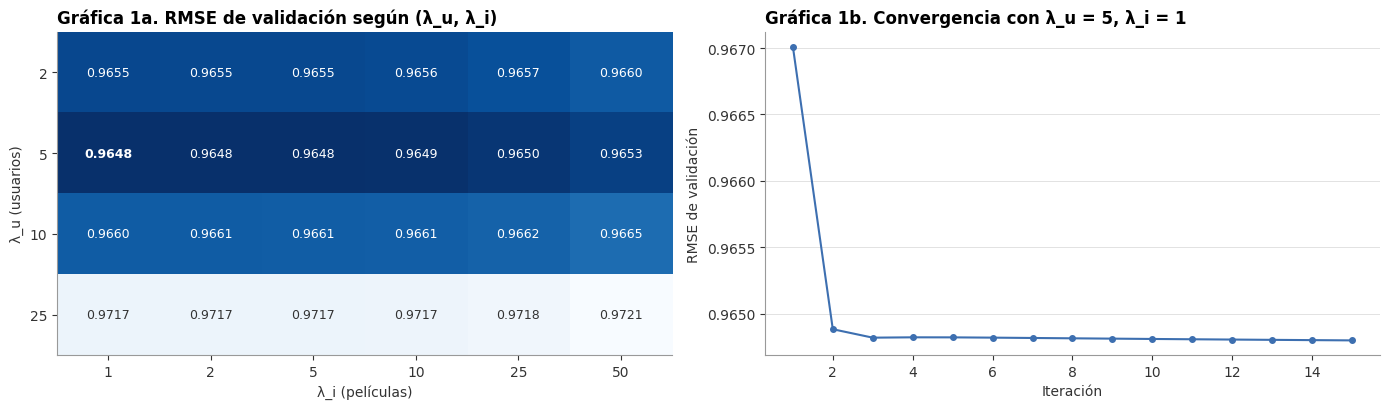

RMSE de validación de referencia: media global: 1.1181 | media + b_i: 1.0437
RMSE por iteración: 0.96701 0.96488 0.96482 0.96482 0.96482 0.96482 … 0.96480
[RAM] 2. rejilla del baseline: proceso 1.33 GB | libre en el sistema 4.63 GB


In [4]:
# Una iteración de mínimos cuadrados alternados sobre los sesgos, recorriendo la CSR (solo las entradas con usar = True)
@njit
def iteracion_sesgos(indptr, indices, datos, usar, mu, bu, bi, lam_u, lam_i):
    num, cnt = np.zeros(len(bi)), np.zeros(len(bi))
    for u in range(len(bu)):
        for k in range(indptr[u], indptr[u + 1]):
            if usar[k]:
                num[indices[k]] += datos[k] - mu - bu[u]
                cnt[indices[k]] += 1
    for i in range(len(bi)):
        bi[i] = num[i] / (lam_i + cnt[i])
    for u in range(len(bu)):
        s, c = 0.0, 0
        for k in range(indptr[u], indptr[u + 1]):
            if usar[k]:
                s += datos[k] - mu - bi[indices[k]]
                c += 1
        bu[u] = s / (lam_u + c)


def ajustar_sesgos(X, usar, lam_u, lam_i, iteraciones=10, val=None):
    # Devuelve (μ, b_u, b_i) y, si se da val = (u, i, r), el RMSE de validación tras cada iteración
    mu = np.sum(X.data, where=usar, dtype=np.float64) / usar.sum()
    bu, bi = np.zeros(X.shape[0]), np.zeros(X.shape[1])
    historia = []
    for _ in range(iteraciones):
        iteracion_sesgos(X.indptr, X.indices, X.data, usar, mu, bu, bi, lam_u, lam_i)
        if val is not None:
            historia.append(rmse(mu + bu[val[0]] + bi[val[1]], val[2]))
    return mu, bu, bi, historia


# Búsqueda de (λ_u, λ_i) con validación tipo probe sobre los 99 millones de ratings
LAMBDAS_U, LAMBDAS_I = [2, 5, 10, 25], [1, 2, 5, 10, 25, 50]
t0 = time.perf_counter()
usar = ~es_val
rejilla = pd.DataFrame(index=pd.Index(LAMBDAS_U, name="λ_u"), columns=pd.Index(LAMBDAS_I, name="λ_i"), dtype=float)
for lam_u in LAMBDAS_U:
    for lam_i in LAMBDAS_I:
        rejilla.loc[lam_u, lam_i] = ajustar_sesgos(R, usar, lam_u, lam_i, 6, (val_u, val_i, val_r))[3][-1]
LAM_U, LAM_I = rejilla.stack().idxmin()
print(f"Rejilla de {rejilla.size} combinaciones × 6 iteraciones: {time.perf_counter() - t0:.0f} s | "
      f"mejor: λ_u = {LAM_U}, λ_i = {LAM_I}, RMSE de validación = {rejilla.loc[LAM_U, LAM_I]:.4f}")

# Convergencia con los λ elegidos, y modelos más simples como referencia
_, _, _, historia = ajustar_sesgos(R, usar, LAM_U, LAM_I, 15, (val_u, val_i, val_r))
mu_v = np.sum(R.data, where=usar, dtype=np.float64) / usar.sum()
_, _, _, hist_pel = ajustar_sesgos(R, usar, np.inf, LAM_I, 1, (val_u, val_i, val_r))
referencias_val = {"media global": rmse(np.full(len(val_r), mu_v), val_r), "media + b_i": hist_pel[-1]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
im = ax1.imshow(rejilla.to_numpy(), cmap="Blues_r", aspect="auto")
for (a, b), v in np.ndenumerate(rejilla.to_numpy()):
    ax1.text(b, a, f"{v:.4f}", ha="center", va="center", fontsize=9,
             color="white" if v < rejilla.to_numpy().mean() else TINTA, fontweight="bold" if v == rejilla.min().min() else None)
ax1.set_xticks(range(len(LAMBDAS_I)), labels=LAMBDAS_I)
ax1.set_yticks(range(len(LAMBDAS_U)), labels=LAMBDAS_U)
estilo_ejes(ax1, "Gráfica 1a. RMSE de validación según (λ_u, λ_i)", "λ_i (películas)", "λ_u (usuarios)", rejilla=None)
ax2.plot(range(1, len(historia) + 1), historia, color=AZUL, marker="o", markersize=4)
estilo_ejes(ax2, f"Gráfica 1b. Convergencia con λ_u = {LAM_U}, λ_i = {LAM_I}", "Iteración", "RMSE de validación")
plt.tight_layout()
plt.show()
print("RMSE de validación de referencia: " + " | ".join(f"{k}: {v:.4f}" for k, v in referencias_val.items()))
print("RMSE por iteración: " + " ".join(f"{h:.5f}" for h in historia[:6]) + " …" + f" {historia[-1]:.5f}")
del usar
gc.collect()
ram("2. rejilla del baseline")

**Observaciones y decisión: ajuste del baseline**

- **Elección de $\lambda$ (Gráfica 1a).** El mínimo es $\lambda_u = 5$, $\lambda_i = 1$, con RMSE de validación
  **0.9648**.
  - En $\lambda_i$ la superficie es **plana**: de 1 a 10 el RMSE cambia a lo más 0.0001. Las películas tienen muchos
    ratings (mediana de 546), así que $\lambda_i \ll |R(i)|$ y la regularización casi no las toca. Por eso no ampliamos
    más la rejilla aunque el mínimo quede en el borde.
  - $\lambda_u$ sí importa: con 25 el RMSE sube a **0.9717**. Los usuarios tienen menos ratings (mediana de 93; el 13 %
    tiene menos de 20) y sus sesgos son más sensibles al encogimiento.
- **Convergencia (Gráfica 1b).** Los mínimos cuadrados alternados convergen en **2 o 3 iteraciones**: 0.9670 en la
  primera y 0.9648 desde la tercera. Cada ajuste sobre los 99 millones tarda unos segundos.
- **Cada término aporta.** En validación, la media global da **1.1181**, el sesgo de película la baja a **1.0437** y el
  del usuario a **0.9648**. El sesgo de usuario reduce el error más que el de película, porque la gente usa la escala de
  forma muy distinta.

**Modelo final.** Reentrenamos con todo el entrenamiento y los $\lambda$ elegidos, y evaluamos en el probe completo.
Como referencia incluimos la media global sola y la media más el sesgo de película.

In [5]:
# Baseline final sobre los 99 millones de ratings, RMSE en el probe completo y comparación con Cinematch
t0 = time.perf_counter()
todos = np.ones(R.nnz, dtype=bool)
mu, bu, bi, _ = ajustar_sesgos(R, todos, LAM_U, LAM_I, 10)
segundos_baseline = time.perf_counter() - t0
_, _, bi_solo, _ = ajustar_sesgos(R, todos, np.inf, LAM_I, 1)
np.savez(RUTA_MODELOS / "baseline_completo.npz", mu=mu, bu=bu, bi=bi, lam_u=LAM_U, lam_i=LAM_I)

pred_probe = np.clip(mu + bu[probe_u] + bi[probe_m], 1, 5)
np.save(RUTA_PREDICCIONES / "baseline_probe.npy", pred_probe.astype(np.float32))
rmse_baseline = rmse(pred_probe, probe_r)
tabla = pd.DataFrame({"RMSE probe": {
    "media global μ": rmse(np.full(len(probe_r), mu), probe_r),
    "μ + b_i": rmse(mu + bi_solo[probe_m], probe_r),
    "μ + b_u + b_i (baseline)": rmse_baseline,
    "Cinematch (Netflix)": CINEMATCH_PROBE,
}})
tabla["vs. Cinematch"] = (tabla["RMSE probe"] / CINEMATCH_PROBE - 1).map(lambda v: f"{100 * v:+.2f} %")
display(tabla.round(4))
print(f"Ajuste: {segundos_baseline:.1f} s (10 iteraciones sobre {R.nnz:,} ratings) | μ = {mu:.4f} | "
      f"b_u en [{bu.min():.2f}, {bu.max():.2f}] | b_i en [{bi.min():.2f}, {bi.max():.2f}]")

# Películas con mayor y menor sesgo entre las que tienen ≥ 1,000 ratings
peliculas = pd.read_parquet(RUTA_PROCESADOS / "peliculas.parquet")
peliculas["b_i"] = bi
con_datos = peliculas[peliculas["n_train"] >= 1000]
display(pd.concat({"mayor b_i": con_datos.nlargest(5, "b_i"), "menor b_i": con_datos.nsmallest(5, "b_i")})
        [["year", "title", "n_train", "media_train", "b_i"]].round(3))

,RMSE probe,vs. Cinematch
media global μ,1.1296,+19.23 %
μ + b_i,1.0528,+11.13 %
μ + b_u + b_i (baseline),0.9822,+3.68 %
Cinematch (Netflix),0.9474,+0.00 %


Ajuste: 12.9 s (10 iteraciones sobre 99,072,112 ratings) | μ = 3.6033 | b_u en [-2.61, 1.86] | b_i en [-2.30, 1.10]


year                                                                     title  n_train  media_train    b_i
mayor b_i 9863   2004                                            Battlestar Galactica: Season 1     1436        4.669  1.100
          3455   2004                                                            Lost: Season 1     5758        4.678  1.098
          14960  2003               Lord of the Rings: The Return of the King: Extended Edition    72600        4.723  1.081
          7229   2001       The Lord of the Rings: The Fellowship of the Ring: Extended Edition    72274        4.716  1.076
          7056   2002                       Lord of the Rings: The Two Towers: Extended Edition    73630        4.702  1.061
menor b_i 9528   2003  National Lampoon's Christmas Vacation 2: Cousin Eddie's Island Adventure     1325        1.981 -1.707
          3020   2003                                                         House of the Dead     5547        1.962 -1.693
          15225  2002                           Sopranos Unauthorized: Shooting Sites Uncovered     1084        1.935 -1.660
          3666   1986                                                         Shanghai Surprise     1189        1.764 -1.657
          12516  2003                                                                     Gigli     9893        1.945 -1.644

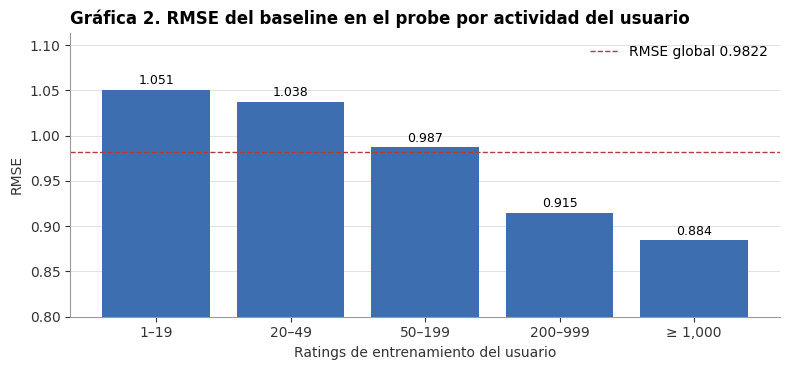

grupo,1–19,20–49,50–199,200–999,"≥ 1,000"
ratings del probe,155061,295524,510679,407634,39497
RMSE,1.0505,1.0375,0.987,0.9148,0.8844
% del probe,11.0 %,21.0 %,36.3 %,28.9 %,2.8 %


[RAM] 2. baseline completo: proceso 1.47 GB | libre en el sistema 4.52 GB


In [6]:
# Gráfica 2. RMSE del baseline en el probe según la actividad del usuario
n_usuario = np.diff(R.indptr)[probe_u]
cortes = [0, 20, 50, 200, 1000, np.inf]
etiquetas = ["1–19", "20–49", "50–199", "200–999", "≥ 1,000"]
grupo = pd.cut(n_usuario, cortes, right=False, labels=etiquetas)
por_grupo = pd.DataFrame({"err2": (pred_probe - probe_r) ** 2, "grupo": grupo}).groupby("grupo", observed=True)["err2"]
por_grupo = pd.DataFrame({"ratings del probe": por_grupo.size(), "RMSE": np.sqrt(por_grupo.mean())})
por_grupo["% del probe"] = (por_grupo["ratings del probe"] / len(probe_r)).map(lambda v: pct(v, 1))

fig, ax = plt.subplots(figsize=(8, 3.8))
barras = ax.bar(etiquetas, por_grupo["RMSE"], color=AZUL)
ax.bar_label(barras, labels=[f"{v:.3f}" for v in por_grupo["RMSE"]], fontsize=9, padding=2)
ax.axhline(rmse_baseline, color=ROJO, linestyle="--", linewidth=1, label=f"RMSE global {rmse_baseline:.4f}")
ax.set_ylim(0.8, por_grupo["RMSE"].max() * 1.06)
ax.legend()
estilo_ejes(ax, "Gráfica 2. RMSE del baseline en el probe por actividad del usuario",
            "Ratings de entrenamiento del usuario", "RMSE")
plt.tight_layout()
plt.show()
display(por_grupo.round(4).T)
ram("2. baseline completo")

**Observaciones: baseline en el probe**

- **RMSE en el probe completo: 0.9822**, a **3.68 %** de Cinematch (0.9474). Sin ninguna interacción usuario-película,
  media + sesgos queda a menos de 0.035 del sistema que Netflix usaba en producción. La media sola da **1.1296** y con el
  sesgo de película, **1.0528**.
- **Probe contra validación.** El RMSE del probe (0.9822) es mayor que el de validación (0.9648). Los dos son
  recientes, pero el probe tiene hasta 9 ratings por usuario y pesa más a los usuarios con poca historia (notebook 1,
  sección 1.6).
- **La actividad del usuario lo explica (Gráfica 2).** El RMSE baja de **1.0505** en usuarios con menos de 20 ratings a
  **0.8844** en los que tienen 1,000 o más. Los usuarios con menos de 50 ratings aportan el **32 %** del probe con RMSE
  mayor que 1.03: son el caso difícil para cualquier modelo.
- **Los sesgos de película tienen sentido.**
  - Los más altos son las ediciones extendidas de *El Señor de los Anillos* y temporadas de series (*Lost*,
    *Battlestar Galactica*): las califica sobre todo su público fiel.
  - Los más bajos son fracasos conocidos como *Gigli* y *House of the Dead*.
  - El ajuste completo tarda **10.7 s**.

**Baseline en S.** Para comparar con los modelos que solo ven S, ajustamos el mismo baseline (con los mismos $\lambda$)
**solo con los ratings de S** y lo evaluamos en el probe de S. También evaluamos ahí el baseline completo, que ve todos
los ratings de esos usuarios y películas. El top-N del baseline ordena por $b_i$, porque $\mu + b_u$ es igual para
todas las películas de un usuario. Como referencia no personalizada agregamos la **popularidad**: ordenar por número de
ratings.

In [7]:
# Baseline ajustado solo con S, baseline completo evaluado en el probe de S, y top-N de baseline y popularidad
t0 = time.perf_counter()
S_mu, S_bu, S_bi, _ = ajustar_sesgos(S_R, np.ones(S_R.nnz, dtype=bool), LAM_U, LAM_I, 10)
segundos_S = time.perf_counter() - t0
np.savez(RUTA_MODELOS / "baseline_S.npz", mu=S_mu, bu=S_bu, bi=S_bi, lam_u=LAM_U, lam_i=LAM_I)
S_base_probe = np.clip(S_mu + S_bu[S_probe_u] + S_bi[S_probe_m], 1, 5)
np.save(RUTA_PREDICCIONES / "baseline_S.npy", S_base_probe.astype(np.float32))

completo_en_S = np.clip(mu + bu[S_usuarios[S_probe_u]] + bi[S_peliculas[S_probe_m]], 1, 5)
popularidad = np.diff(S_R.tocsc().indptr).astype(np.float32)

t0 = time.perf_counter()
topn_baseline = evaluar_topn(lambda us: np.broadcast_to(S_bi, (len(us), n_S_pel)))
segundos_topn_baseline = time.perf_counter() - t0
topn_popularidad = evaluar_topn(lambda us: np.broadcast_to(popularidad, (len(us), n_S_pel)))

guardar_resultado("Popularidad", tipo="top-N", escala="S", **topn_popularidad)
guardar_resultado("Baseline (completo)", tipo="predicción", escala="completo (99 M)", rmse_probe=rmse_baseline,
                  rmse_probe_S=rmse(completo_en_S, S_probe_r), segundos_entrenamiento=segundos_baseline)
guardar_resultado("Baseline (S)", tipo="predicción y top-N", escala="S", rmse_probe_S=rmse(S_base_probe, S_probe_r),
                  segundos_entrenamiento=segundos_S, segundos_topn=segundos_topn_baseline, **topn_baseline)

display(pd.DataFrame({
    "RMSE probe S": [rmse(completo_en_S, S_probe_r), rmse(S_base_probe, S_probe_r), np.nan],
    **{m: [np.nan, topn_baseline[m], topn_popularidad[m]] for m in topn_baseline},
}, index=["baseline completo (99 M)", "baseline ajustado en S", "popularidad"]).round(4))

# Top-10 de dos ordenamientos no personalizados
display(pd.DataFrame({
    "por b_i (baseline)": peliculas.loc[S_peliculas[np.argsort(-S_bi)[:10]], "title"].to_numpy(),
    "por popularidad": peliculas.loc[S_peliculas[np.argsort(-popularidad)[:10]], "title"].to_numpy(),
}, index=range(1, 11)))
del R, es_val, todos, pred_probe, n_usuario, grupo
gc.collect()
ram("2. baseline en S")

,RMSE probe S,P@10,R@10,NDCG@10
baseline completo (99 M),0.9753,NaN,NaN,NaN
baseline ajustado en S,0.9760,0.0021,0.0097,0.0066
popularidad,NaN,0.0053,0.0248,0.0146


,por b_i (baseline),por popularidad
1,Lost: Season 1,Miss Congeniality
2,Lord of the Rings: The Return of the King: Extended Edition,Independence Day
3,The Lord of the Rings: The Fellowship of the Ring: Extended Edition,The Patriot
4,Lord of the Rings: The Two Towers: Extended Edition,The Day After Tomorrow
5,Arrested Development: Season 2,Pretty Woman
6,The Sopranos: Season 5,Pirates of the Caribbean: The Curse of the Black Pearl
7,The West Wing: Season 3,The Green Mile
8,The Shawshank Redemption: Special Edition,Forrest Gump
9,Band of Brothers,Con Air
10,Ken Burns' Civil War,Twister


[RAM] 2. baseline en S: proceso 470.9 MB | libre en el sistema 5.53 GB


**Observaciones: baseline en S y referencias top-N**

- **Entrenar solo con S casi no cuesta.** En el probe de S, el baseline completo da **0.9753** y el ajustado solo con S
  **0.9760**. La diferencia (0.0007) acota lo que pierden los modelos de S por no ver el resto de los datos.
- **El probe de S es más fácil que el completo** (0.9753 contra 0.9822 con el mismo modelo), porque excluye las películas
  poco populares. Los RMSE de S **no se comparan** directamente con Cinematch; la comparación justa es contra el baseline
  de S.
- **En top-N, el baseline pierde contra la popularidad.**
  - Popularidad: P@10 = **0.0053**, R@10 = **0.0248** y NDCG@10 = **0.0146**.
  - Ordenar por $b_i$: **0.0021**, **0.0097** y **0.0066**.

  El baseline recomienda lo que se califica **alto** (ediciones extendidas, temporadas de series), y una película solo
  cuenta como acierto si el usuario la **calificó** en el probe, lo que favorece a las populares. Predecir bien el rating
  no es lo mismo que ordenar bien (Cremonesi, Koren y Turrin, 2010). La popularidad es la referencia que un modelo top-N
  tiene que superar.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">RECOMENDACIÓN · VECINDARIO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Filtrado colaborativo ítem-ítem</span></div>



**Idea.** Para predecir cuánto le gustará a $u$ la película $i$, buscamos entre las películas que $u$ **ya calificó**
las $k$ más parecidas a $i$ y promediamos lo que $u$ les dio. Usamos vecindario ítem-ítem y no usuario-usuario porque
hay 20 veces más usuarios que películas: la matriz de similitudes de S es de 5,000 × 5,000 (100 MB en `float32`) y las
similitudes entre películas, con miles de ratings cada una, son más estables (MMDS, sección 9.3).

**Similitudes.** Cada película es un vector columna de $R$ sobre los usuarios, con 0 donde no hay rating:

- **coseno:** $s_{ij} = \dfrac{r_i \cdot r_j}{\lVert r_i \rVert \lVert r_j \rVert}$ sobre los ratings crudos. Como todos
  los ratings son positivos, dos películas cualesquiera con usuarios en común salen parecidas;
- **Pearson centrada:** el mismo coseno, pero sobre los ratings menos la media de cada película,
  $\tilde r_{ui} = r_{ui} - \bar r_i$. Un rating por debajo de la media de la película cuenta como negativo (MMDS, 9.3.1).

Calculamos los productos punto como la matriz de Gram $R^\top R$ por bloques de 8,000 usuarios densificados, con
`ssyrk` de BLAS. Con la misma operación sobre la matriz binaria obtenemos $n_{ij}$, el número de usuarios que
calificaron ambas.

**Shrinkage.** Una similitud basada en pocos usuarios en común es ruidosa. Seguimos a Koren (2008) y la encogemos:
$s_{ij} \leftarrow \frac{n_{ij}}{n_{ij} + \lambda}\, s_{ij}$.

**Predicción.** Con $N^k(i; u)$ las $k$ películas calificadas por $u$ con mayor similitud **positiva** con $i$:

- **promedio ponderado** (MMDS): $\hat r_{ui} = \dfrac{\sum_{j \in N^k(i;u)} s_{ij}\, r_{uj}}{\sum_{j} s_{ij}}$;
- **sobre el baseline** (Koren, 2008, ec. 3): $\hat r_{ui} = b_{ui} + \dfrac{\sum_{j \in N^k(i;u)} s_{ij}\,(r_{uj} - b_{uj})}{\sum_{j} s_{ij}}$.
  Los vecinos explican solo lo que el baseline no explica.

Si $u$ no tiene ninguna película con similitud positiva, la predicción es $b_{ui}$.

In [8]:
# Submatriz con las entradas marcadas, Gram por bloques con BLAS y similitudes con shrinkage
def sub_csr(X, conservar):
    filas = np.repeat(np.arange(X.shape[0], dtype=np.int32), np.diff(X.indptr))[conservar]
    indptr = np.zeros(X.shape[0] + 1, dtype=np.int32)
    indptr[1:] = np.cumsum(np.bincount(filas, minlength=X.shape[0]))
    return sp.csr_matrix((X.data[conservar], X.indices[conservar], indptr), shape=X.shape)


def gram(X, bloque=8_000):
    # Xᵀ X sumando bloques de filas densificados; ssyrk llena solo el triángulo superior
    G = np.zeros((X.shape[1], X.shape[1]), dtype=np.float32, order="F")
    for a in range(0, X.shape[0], bloque):
        G = ssyrk(1.0, X[a:a + bloque].toarray(), beta=1.0, c=G, trans=1, overwrite_c=1)
    G = np.triu(G)
    return np.ascontiguousarray(G + np.triu(G, 1).T)


def gramianas(X, mu, bu, bi):
    # Gram de ratings crudos, centrados por la media de la película y binaria (n_ij), y residuos sobre el baseline
    filas = np.repeat(np.arange(X.shape[0], dtype=np.int32), np.diff(X.indptr))
    media_pel = np.bincount(X.indices, weights=X.data, minlength=X.shape[1]) / np.maximum(np.bincount(X.indices, minlength=X.shape[1]), 1)
    centrada = sp.csr_matrix(((X.data - media_pel[X.indices]).astype(np.float32), X.indices, X.indptr), shape=X.shape)
    binaria = sp.csr_matrix((np.ones(X.nnz, dtype=np.float32), X.indices, X.indptr), shape=X.shape)
    residuos = (X.data - mu - bu[filas] - bi[X.indices]).astype(np.float32)
    return {"coseno": gram(X), "pearson": gram(centrada)}, gram(binaria), residuos


def similitud(G, N, lam):
    d = np.sqrt(np.diag(G))
    d[d == 0] = np.inf
    S = G / d[:, None] / d[None, :]
    if lam:
        S *= N / (N + lam)
    np.fill_diagonal(S, 0)
    return S.astype(np.float32)


@njit(parallel=True)
def predecir_knn(indptr, indices, valores, sim, us, its, k, base, sobre_baseline):
    # Predicción de cada par (u, i) con los k vecinos de i más similares (similitud > 0) entre los calificados por u
    out = base.copy()
    for t in prange(len(us)):
        a, b = indptr[us[t]], indptr[us[t] + 1]
        if b == a:
            continue
        s = np.empty(b - a, np.float32)
        for q in range(b - a):
            s[q] = sim[its[t], indices[a + q]]
        orden = np.argsort(-s)
        num, den = 0.0, 0.0
        for q in orden[:k]:
            if s[q] <= 0:
                break
            num += s[q] * valores[a + q]
            den += s[q]
        if den > 0:
            out[t] = base[t] + num / den if sobre_baseline else num / den
    return out


# Similitudes con S sin la validación, y baseline de S sin la validación para los residuos
t0 = time.perf_counter()
S_tr = sub_csr(S_R, ~S_es_val)
mu_v, bu_v, bi_v, _ = ajustar_sesgos(S_tr, np.ones(S_tr.nnz, dtype=bool), LAM_U, LAM_I, 10)
G_v, N_v, resid_v = gramianas(S_tr, mu_v, bu_v, bi_v)
base_val = (mu_v + bu_v[S_val_u] + bi_v[S_val_i]).astype(np.float64)
print(f"Gramianas de validación (3 matrices de {n_S_pel:,} × {n_S_pel:,}): {time.perf_counter() - t0:.0f} s | "
      f"RMSE de validación del baseline de S: {rmse(base_val, S_val_r):.4f} | "
      f"n_ij: mediana {np.median(N_v):.0f}, % de pares con n_ij = 0: {pct((N_v == 0).mean())}")
ram("3. gramianas de validación")

Gramianas de validación (3 matrices de 5,000 × 5,000): 114 s | RMSE de validación del baseline de S: 0.9625 | n_ij: mediana 157, % de pares con n_ij = 0: 0.00 %
[RAM] 3. gramianas de validación: proceso 1.02 GB | libre en el sistema 4.98 GB


**Elección de la variante, $k$ y $\lambda$.** Probamos las tres combinaciones de similitud y predicción con
$k \in \{10, 20, 40, 80\}$ y $\lambda \in \{0, 50, 100, 200\}$ sobre la validación tipo probe de S.

48 configuraciones: 47 s


,λ,k,RMSE validación
variante,,,
coseno + promedio ponderado,0,10,0.9955
coseno + baseline,0,20,0.9349
Pearson + baseline,0,20,0.9146


Mejor: Pearson + baseline, k = 20, λ = 0, RMSE de validación = 0.9146


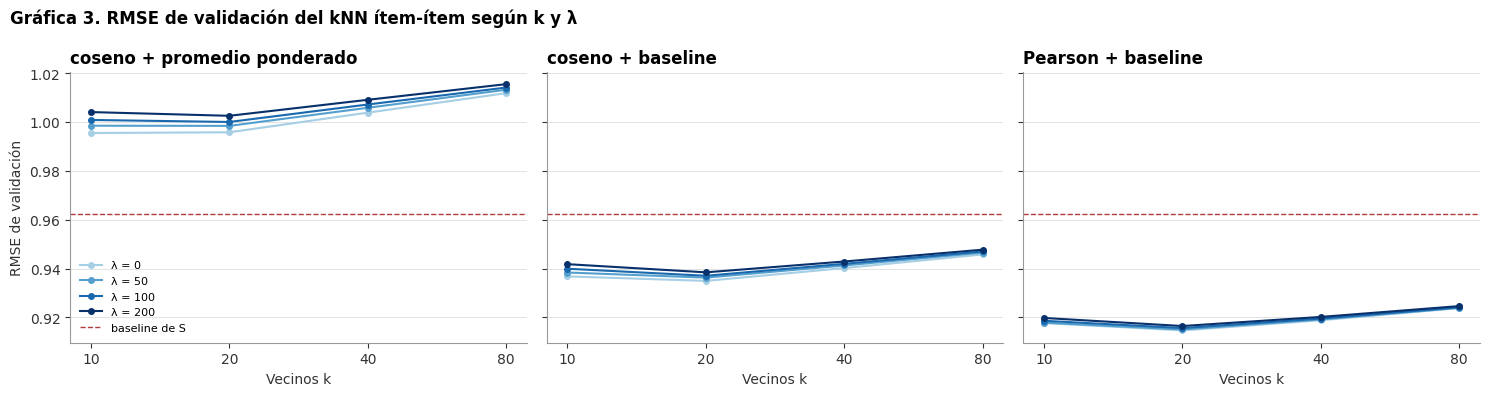

[RAM] 3. rejilla kNN: proceso 594.4 MB | libre en el sistema 5.34 GB


In [9]:
# Rejilla: variante × k × λ con RMSE de validación en S
VARIANTES = {"coseno + promedio ponderado": ("coseno", False), "coseno + baseline": ("coseno", True),
             "Pearson + baseline": ("pearson", True)}
KS, LAMBDAS = [10, 20, 40, 80], [0, 50, 100, 200]
filas_rejilla = []
t0 = time.perf_counter()
for lam in LAMBDAS:
    for nombre, (tipo, sobre_baseline) in VARIANTES.items():
        sim = similitud(G_v[tipo], N_v, lam)
        valores = resid_v if sobre_baseline else S_tr.data
        for k in KS:
            pred = predecir_knn(S_tr.indptr, S_tr.indices, valores, sim, S_val_u, S_val_i, k, base_val, sobre_baseline)
            filas_rejilla.append({"variante": nombre, "λ": lam, "k": k, "RMSE validación": rmse(pred, S_val_r)})
rejilla_knn = pd.DataFrame(filas_rejilla)
print(f"{len(rejilla_knn)} configuraciones: {time.perf_counter() - t0:.0f} s")

mejores = rejilla_knn.loc[rejilla_knn.groupby("variante")["RMSE validación"].idxmin()].set_index("variante")
display(mejores.loc[list(VARIANTES)].round(4))
mejor = rejilla_knn.loc[rejilla_knn["RMSE validación"].idxmin()]
VARIANTE, K_VEC, LAM_VEC = mejor["variante"], int(mejor["k"]), int(mejor["λ"])
print(f"Mejor: {VARIANTE}, k = {K_VEC}, λ = {LAM_VEC}, RMSE de validación = {mejor['RMSE validación']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
colores = plt.cm.Blues(np.linspace(0.35, 1, len(LAMBDAS)))
for ax, nombre in zip(axes, VARIANTES):
    for lam, color in zip(LAMBDAS, colores):
        d = rejilla_knn[(rejilla_knn["variante"] == nombre) & (rejilla_knn["λ"] == lam)]
        ax.plot(d["k"], d["RMSE validación"], marker="o", markersize=4, color=color, label=f"λ = {lam}")
    ax.axhline(rmse(base_val, S_val_r), color=ROJO, linestyle="--", linewidth=1, label="baseline de S")
    ax.set_xscale("log", base=2)
    ax.set_xticks(KS, labels=KS)
    estilo_ejes(ax, nombre, "Vecinos k", "RMSE de validación" if ax is axes[0] else None)
axes[0].legend(fontsize=8)
fig.suptitle("Gráfica 3. RMSE de validación del kNN ítem-ítem según k y λ", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
del G_v, N_v, resid_v, S_tr, sim, pred
gc.collect()
ram("3. rejilla kNN")

**Observaciones y decisión: elección del kNN**

- **Centrar es lo que más importa (Gráfica 3).** En validación:
  - **coseno + promedio ponderado** (la versión clásica): **0.9955**, **peor que el baseline** de S (0.9625). El coseno
    sobre ratings crudos encuentra parecidas a casi todas las películas y el promedio ignora los sesgos;
  - **coseno + baseline**: **0.9349**, porque los vecinos ya solo corrigen el residuo del baseline;
  - **Pearson + baseline**: **0.9146**, el mejor. Al centrar por la media de cada película, la similitud mide si los
    gustos coinciden por encima o por debajo de lo normal, no solo si las vieron los mismos usuarios.
- **Vecinos.** $k = 20$ es el mejor en las dos variantes sobre el baseline. Con 80 vecinos entran películas poco
  parecidas que diluyen la señal.
- **El *shrinkage* no ayuda en S.** $\lambda = 0$ gana en las tres variantes, aunque por poco. Entre las 5,000
  películas más populares, la mediana de usuarios en común es **157** y ningún par tiene $n_{ij} = 0$: casi no hay
  similitudes basadas en pocos datos que encoger. Con todo el catálogo sí sería necesario.
- **Decisión:** Pearson centrada + baseline, $k = 20$, $\lambda = 0$.

**Modelo final.** Recalculamos las similitudes con todo el entrenamiento de S y la configuración elegida, y predecimos el
probe de S. Comparamos también con la mejor configuración de la variante clásica (coseno + promedio ponderado), para
medir cuánto aportan el centrado y el baseline.

**Dos puntajes para el top-N.**

- **Rating predicho** $\hat r_{ui}$, el mismo promedio ponderado **normalizado** que usamos para el RMSE, calculado para
  las 5,000 películas de S.
- **Suma de similitudes sin normalizar** (Deshpande y Karypis, 2004):
  $\text{puntaje}_{ui} = \sum_{j \in R(u),\, r_{uj} \ge 4} \max(s_{ij}, 0)$, sobre las películas que el usuario calificó
  con 4 o 5. Al no dividir entre $\sum_j s_{ij}$, una película gana puntaje por **cuántas** películas que le gustaron
  al usuario se le parecen, no solo por qué tan alto las calificó. Se calcula para todos los usuarios de un lote como un
  producto matriz-matriz. Si el usuario no tiene ratings de 4 o más, todos los puntajes son 0 y el respaldo $b_i$
  (multiplicado por $10^{-6}$) decide el orden.

En los dos puntajes se excluyen las películas que el usuario ya calificó en el entrenamiento.

In [10]:
# kNN final: similitudes con todo S, RMSE en el probe de S y top-N
@njit(parallel=True)
def puntajes_knn(indptr, indices, residuos, sim, usuarios, k, mu, bu, bi):
    # Predicción sobre el baseline para todas las películas de S, para cada usuario de la lista
    P = np.empty((len(usuarios), sim.shape[0]), np.float32)
    for t in range(len(usuarios)):
        u = usuarios[t]
        a, b = indptr[u], indptr[u + 1]
        for i in prange(sim.shape[0]):
            s = np.empty(b - a, np.float32)
            for q in range(b - a):
                s[q] = sim[i, indices[a + q]]
            orden = np.argsort(-s)
            num, den = 0.0, 0.0
            for q in orden[:k]:
                if s[q] <= 0:
                    break
                num += s[q] * residuos[a + q]
                den += s[q]
            P[t, i] = mu + bu[u] + bi[i] + (num / den if den > 0 else 0.0)
    return P


t0 = time.perf_counter()
G, N, residuos = gramianas(S_R, S_mu, S_bu, S_bi)
tipo, sobre_baseline = VARIANTES[VARIANTE]
SIM = similitud(G[tipo], N, LAM_VEC)
segundos_knn = time.perf_counter() - t0
np.save(RUTA_MODELOS / "knn_similitud_S.npy", SIM)
np.save(RUTA_MODELOS / "knn_coocurrencias_S.npy", N.astype(np.int32))

base_S = S_base_probe.astype(np.float64)
t0 = time.perf_counter()
pred_knn = np.clip(predecir_knn(S_R.indptr, S_R.indices, residuos, SIM, S_probe_u, S_probe_m, K_VEC, base_S, True), 1, 5)
segundos_pred = time.perf_counter() - t0
np.save(RUTA_PREDICCIONES / "knn_S.npy", pred_knn.astype(np.float32))

clasica = mejores.loc["coseno + promedio ponderado"]
sim_clasica = similitud(G["coseno"], N, int(clasica["λ"]))
pred_clasica = predecir_knn(S_R.indptr, S_R.indices, S_R.data, sim_clasica, S_probe_u, S_probe_m, int(clasica["k"]),
                            base_S, False)
del sim_clasica, G
gc.collect()

t0 = time.perf_counter()
topn_knn = evaluar_topn(lambda us: puntajes_knn(S_R.indptr, S_R.indices, residuos, SIM, us, K_VEC, S_mu, S_bu, S_bi))
segundos_topn = time.perf_counter() - t0

# Puntaje sin normalizar (Deshpande y Karypis, 2004): suma de similitudes positivas con las películas calificadas con ≥ 4
SIM_POS = np.maximum(SIM, 0)
GUSTA = sp.csr_matrix(((S_R.data >= 4).astype(np.float32), S_R.indices.copy(), S_R.indptr.copy()), shape=S_R.shape)
GUSTA.eliminate_zeros()  # con copias: eliminate_zeros modifica los arreglos en su lugar
t0 = time.perf_counter()
topn_suma = evaluar_topn(lambda us: GUSTA[us] @ SIM_POS + 1e-6 * S_bi)
segundos_topn_suma = time.perf_counter() - t0
sin_gustos = (np.diff(GUSTA.indptr)[U_EVAL] == 0).mean()
del SIM_POS
gc.collect()

guardar_resultado("kNN ítem-ítem", tipo="predicción y top-N", escala="S", rmse_probe_S=rmse(pred_knn, S_probe_r),
                  segundos_entrenamiento=segundos_knn, segundos_prediccion=segundos_pred, segundos_topn=segundos_topn,
                  configuracion=f"{VARIANTE}, k = {K_VEC}, λ = {LAM_VEC}", **topn_knn)
guardar_resultado("kNN ítem-ítem (suma de similitudes)", tipo="top-N", escala="S", segundos_topn=segundos_topn_suma,
                  configuracion=f"suma de similitudes {VARIANTE.split(' +')[0]} > 0 con películas calificadas ≥ 4",
                  **topn_suma)
sin_vecinos = np.isclose(pred_knn, np.clip(base_S, 1, 5)).mean()
display(pd.DataFrame({
    "RMSE probe S": [np.nan, rmse(S_base_probe, S_probe_r), rmse(pred_clasica, S_probe_r), rmse(pred_knn, S_probe_r), np.nan],
    **{m: [topn_popularidad[m], topn_baseline[m], np.nan, topn_knn[m], topn_suma[m]] for m in topn_knn},
}, index=["popularidad", "baseline de S", f"coseno + promedio ponderado (k = {int(clasica['k'])}, λ = {int(clasica['λ'])})",
          f"{VARIANTE} (k = {K_VEC}, λ = {LAM_VEC}): rating predicho",
          f"{VARIANTE.split(' +')[0]}: suma de similitudes sin normalizar"]).round(4))
print(f"Similitudes: {segundos_knn:.0f} s | predicción de {len(S_probe_r):,} ratings: {segundos_pred:.1f} s | "
      f"top-N de {len(U_EVAL):,} usuarios × {n_S_pel:,} películas: rating predicho {segundos_topn:.0f} s, "
      f"suma de similitudes {segundos_topn_suma:.1f} s | predicciones iguales al baseline: {pct(sin_vecinos)} | "
      f"usuarios evaluados sin ratings ≥ 4 en S: {pct(sin_gustos)}")
ram("3. kNN final")

,RMSE probe S,P@10,R@10,NDCG@10
popularidad,NaN,0.0053,0.0248,0.0146
baseline de S,0.9760,0.0021,0.0097,0.0066
"coseno + promedio ponderado (k = 10, λ = 0)",1.0142,NaN,NaN,NaN
"Pearson + baseline (k = 20, λ = 0): rating predicho",0.9312,0.0036,0.0181,0.0109
Pearson: suma de similitudes sin normalizar,NaN,0.0162,0.0780,0.0490


Similitudes: 110 s | predicción de 262,954 ratings: 2.2 s | top-N de 5,000 usuarios × 5,000 películas: rating predicho 205 s, suma de similitudes 2.1 s | predicciones iguales al baseline: 0.44 % | usuarios evaluados sin ratings ≥ 4 en S: 0.10 %
[RAM] 3. kNN final: proceso 1.04 GB | libre en el sistema 5.17 GB


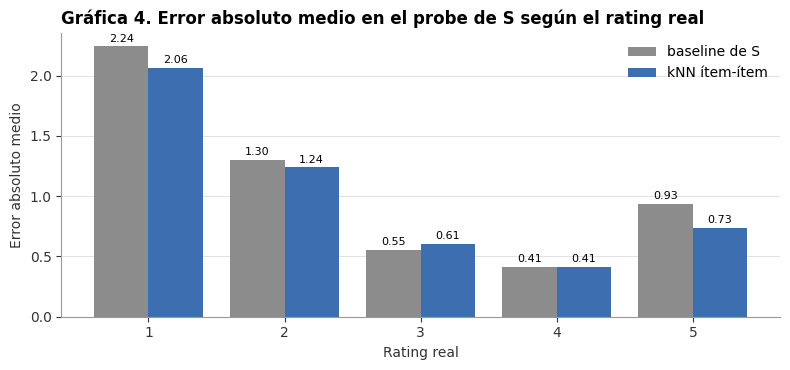

In [11]:
# Gráfica 4. Error absoluto del baseline y del kNN en el probe de S, por rating real
err = pd.DataFrame({"rating": S_probe_r, "baseline de S": np.abs(S_base_probe - S_probe_r),
                    "kNN ítem-ítem": np.abs(pred_knn - S_probe_r)}).groupby("rating").mean()
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(1, 6)
for desplaz, (col, color) in zip([-0.2, 0.2], [("baseline de S", GRIS), ("kNN ítem-ítem", AZUL)]):
    barras = ax.bar(x + desplaz, err[col], width=0.4, color=color, label=col)
    ax.bar_label(barras, labels=[f"{v:.2f}" for v in err[col]], fontsize=8, padding=2)
ax.set_xticks(x)
ax.legend()
estilo_ejes(ax, "Gráfica 4. Error absoluto medio en el probe de S según el rating real", "Rating real",
            "Error absoluto medio")
plt.tight_layout()
plt.show()

**Observaciones: kNN en el probe de S**

- **RMSE en el probe de S: 0.9312**, contra **0.9760** del baseline de S, una mejora del **4.6 %**. Es el mismo orden
  de mejora que separa a Cinematch del baseline en el probe completo (3.5 %). La versión clásica (coseno + promedio)
  da **1.0142**: peor que el baseline también en el probe.
- **Respaldo.** Solo el **0.44 %** de las predicciones queda igual al baseline, por falta de vecinos con similitud
  positiva o porque el usuario no tiene ratings en S.
- **Dónde mejora (Gráfica 4).** En los extremos:
  - con rating real 5, el error absoluto baja de **0.93** a **0.73**;
  - con rating real 1, de **2.24** a **2.06**.

  Con 3 empeora un poco (0.55 a 0.61). El baseline encoge todo hacia la media del usuario y de la película; los vecinos
  lo separan de ella cuando el usuario tiene gustos marcados, y a veces se equivocan.
- **Top-N: el puntaje importa más que el modelo.** Con las mismas similitudes:
  - **rating predicho** (normalizado): P@10 = **0.0036**, R@10 = **0.0181** y NDCG@10 = **0.0109**. Es 1.7 veces el
    baseline, pero sigue **debajo de la popularidad** (0.0053 / 0.0248 / 0.0146);
  - **suma de similitudes sin normalizar** (Deshpande y Karypis, 2004): P@10 = **0.0162**, R@10 = **0.0780** y
    NDCG@10 = **0.0490**. Es **3 veces la popularidad** y 4.5 veces el rating predicho.

  La normalización $\sum_j s_{ij}\, r_{uj} / \sum_j s_{ij}$ responde "¿qué rating le daría?": una película de
  nicho con un solo vecino muy parecido y bien calificado obtiene un rating alto. La suma responde "¿cuánta evidencia
  hay de que le interese?": crece con el número de películas que le gustaron y se le parecen. Para ordenar, lo que
  importa es lo segundo. Además, la suma se calcula como un producto de matrices en **2 s**, contra 205 s del rating
  predicho película por película.
- **Costo.** Las tres matrices de Gram de 5,000 × 5,000 tardan **1.5 a 2 min**. Predecir los 262,954 ratings tarda **2 s**. La matriz de similitudes ocupa 100 MB.

**Vecinos de algunas películas.** Para interpretar las similitudes, mostramos las 8 películas más similares a cuatro
películas populares de géneros distintos, con su similitud final (Pearson o coseno con *shrinkage*) y el número de
usuarios de S que calificaron ambas.

In [12]:
# Las 8 películas más similares a cuatro películas conocidas, según la similitud final del kNN
local = pd.Series(np.arange(n_S_pel), index=S_peliculas)
ejemplos = [2451, 11063, 15069, 14620]  # Fellowship of the Ring, Pulp Fiction, Sex and the City T2, Shrek
tablas = {}
for m in ejemplos:
    i = local[m]
    vecinos = np.argsort(-SIM[i])[:8]
    tablas[f"{peliculas.loc[m, 'title']} ({peliculas.loc[m, 'year']})"] = pd.DataFrame({
        "vecina": [f"{peliculas.loc[S_peliculas[j], 'title']} ({peliculas.loc[S_peliculas[j], 'year']})" for j in vecinos],
        "similitud": SIM[i, vecinos].round(3), "n_ij": N[i, vecinos].astype(int)}, index=range(1, 9))
for nombre, t in tablas.items():
    print(nombre)
    display(t)

Lord of the Rings: The Fellowship of the Ring (2001)


,vecina,similitud,n_ij
1,Lord of the Rings: The Two Towers (2002),0.556,25916
2,Lord of the Rings: The Return of the King (2003),0.462,23015
3,The Lord of the Rings: The Fellowship of the Ring: Extended Edition (2001),0.263,13631
4,Lord of the Rings: The Two Towers: Extended Edition (2002),0.262,13918
5,Lord of the Rings: The Return of the King: Extended Edition (2003),0.244,13561
6,Spider-Man (2002),0.159,19904
7,The Matrix (1999),0.159,20880
8,Pirates of the Caribbean: The Curse of the Black Pearl (2003),0.158,24703


Pulp Fiction (1994)


,vecina,similitud,n_ij
1,Reservoir Dogs (1992),0.234,14986
2,American Beauty (1999),0.232,21398
3,Fight Club (1999),0.211,18634
4,Kill Bill: Vol. 1 (2003),0.200,17871
5,Apocalypse Now (1979),0.176,13450
6,Kill Bill: Vol. 2 (2004),0.173,14993
7,GoodFellas: Special Edition (1990),0.172,14001
8,Memento (2000),0.170,17677


Sex and the City: Season 2 (1999)


,vecina,similitud,n_ij
1,Sex and the City: Season 3 (2000),0.488,6145
2,Sex and the City: Season 1 (1998),0.469,6206
3,Sex and the City: Season 4 (2001),0.382,5211
4,Sex and the City: Season 5 (2002),0.325,4926
5,Sex and the City: Season 6: Part 1 (2003),0.279,4705
6,Sex and the City: Season 6: Part 2 (2004),0.241,3929
7,Friends: Season 2 (1995),0.145,2189
8,Friends: Season 1 (1994),0.142,2057


Shrek (Full-screen) (2001)


,vecina,similitud,n_ij
1,Shrek 2 (2004),0.295,18920
2,"Monsters, Inc. (2001)",0.222,19102
3,Finding Nemo (Widescreen) (2003),0.204,19613
4,Ice Age (2002),0.171,12372
5,A Bug's Life (1998),0.161,11377
6,The Lion King: Special Edition (1994),0.158,10821
7,Harry Potter and the Sorcerer's Stone (2001),0.152,14834
8,Harry Potter and the Chamber of Secrets (2002),0.149,14654


**Observaciones: vecinos**

- **Sin metadatos, el kNN descubre estructura con sentido** solo a partir de los ratings:
  - **sagas y temporadas:** las secuelas de *El Señor de los Anillos* y las otras temporadas de *Sex and the City*
    ocupan los primeros lugares;
  - **director:** las vecinas de *Pulp Fiction* son *Reservoir Dogs* y las dos *Kill Bill* (Tarantino), junto con cine
    de culto de la época (*Fight Club*, *Memento*, *GoodFellas*);
  - **género y público:** *Shrek* tiene como vecinas a *Monsters, Inc.*, *Finding Nemo* e *Ice Age* (animación
    familiar), y después *Harry Potter*. *Sex and the City* lleva a *Friends*.
- **Ediciones duplicadas.** El catálogo trata como películas distintas las ediciones extendidas y en otros formatos; el
  kNN las encuentra muy similares a la original. En las recomendaciones conviene no ofrecer otra edición de algo que el
  usuario ya vio.
- **Las similitudes son moderadas** (0.15 a 0.56) aunque se basen en miles de usuarios en común. Dos películas muy
  relacionadas siguen teniendo públicos que no coinciden del todo.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">RECOMENDACIÓN · RESUMEN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Resumen</span></div>



Resultados guardados en `data/processed/resultados/` para la comparación final del notebook 6.

In [13]:
# Resultados de este notebook y registro de memoria
del SIM, N, residuos, S_R
gc.collect()
ram("4. después de liberar")
resultados = pd.DataFrame([json.load(open(RUTA_RESULTADOS / f"{m}.json", encoding="utf-8"))
                           for m in ["Popularidad", "Baseline (completo)", "Baseline (S)", "kNN ítem-ítem",
                                     "kNN ítem-ítem (suma de similitudes)"]]).set_index("modelo")
display(resultados.drop(columns=["configuracion"], errors="ignore").round(4))
display(pd.DataFrame(registro_ram).set_index("paso"))

[RAM] 4. después de liberar: proceso 613.0 MB | libre en el sistema 5.45 GB


,tipo,escala,P@10,R@10,NDCG@10,rmse_probe,rmse_probe_S,segundos_entrenamiento,segundos_topn,segundos_prediccion
modelo,,,,,,,,,,
Popularidad,top-N,S,0.0053,0.0248,0.0146,NaN,NaN,NaN,NaN,NaN
Baseline (completo),predicción,completo (99 M),NaN,NaN,NaN,0.9822,0.9753,12.8619,NaN,NaN
Baseline (S),predicción y top-N,S,0.0021,0.0097,0.0066,NaN,0.9760,2.2725,0.6734,NaN
kNN ítem-ítem,predicción y top-N,S,0.0036,0.0181,0.0109,NaN,0.9312,110.1400,205.0380,2.1888
kNN ítem-ítem (suma de similitudes),top-N,S,0.0162,0.0780,0.0490,NaN,NaN,NaN,2.0521,NaN


,RAM del proceso,RAM libre del sistema
paso,,
inicio,179.0 MB,5.72 GB
1. validación,1.31 GB,4.64 GB
2. rejilla del baseline,1.33 GB,4.63 GB
2. baseline completo,1.47 GB,4.52 GB
2. baseline en S,470.9 MB,5.53 GB
3. gramianas de validación,1.02 GB,4.98 GB
3. rejilla kNN,594.4 MB,5.34 GB
3. kNN final,1.04 GB,5.17 GB
4. después de liberar,613.0 MB,5.45 GB


**Resumen**

| Modelo | Escala | RMSE probe | RMSE probe S | P@10 | R@10 | NDCG@10 |
|---|---|---|---|---|---|---|
| Popularidad | S | — | — | 0.0053 | 0.0248 | 0.0146 |
| Baseline | completo (99 M) | **0.9822** | 0.9753 | — | — | — |
| Baseline (orden por $b_i$) | S | — | 0.9760 | 0.0021 | 0.0097 | 0.0066 |
| kNN ítem-ítem, rating predicho (Pearson + baseline, k = 20) | S | — | **0.9312** | 0.0036 | 0.0181 | 0.0109 |
| kNN ítem-ítem, suma de similitudes | S | — | — | **0.0162** | **0.0780** | **0.0490** |
| Cinematch (referencia) | completo | 0.9474 | — | — | — | — |

- **Predicción.** El baseline completo queda a 3.7 % de Cinematch en el probe. Sobre S, el kNN ítem-ítem mejora el
  baseline en 4.6 %. Lo que más aporta es **centrar**: usar Pearson y predecir residuos sobre el baseline.
- **Top-N.** Ordenar por rating predicho pierde contra la popularidad. La suma de similitudes sin normalizar, con las
  mismas similitudes, la supera 3 veces. **Predecir y ordenar son tareas distintas**, y en los notebooks siguientes
  reportaremos los dos puntajes cuando el modelo los permita.
- **Memoria.** El pico fue de **1.48 GB** del proceso, con los 99 millones de ratings en CSR. El notebook completo tarda
  unos 15 minutos.
- **Para los siguientes notebooks** quedan guardados los sesgos (`modelos/baseline_*.npz`), las similitudes del kNN, las
  predicciones sobre el probe (`predicciones/`) y las métricas (`resultados/`).